# PINN para la membrana vibrante — Parte computacional

$$\frac{\partial^2U}{\partial t^2}=\frac{\partial^2U}{\partial x^2}+\frac{\partial^2U}{\partial y^2},\qquad U=0 \text{ en los bordes}$$

$$U(x,y,0)=\sin(\pi x)\sin(\pi y),\qquad U_t(x,y,0)=\sqrt2\,\pi\sin(\pi x)\sin(\pi y)$$


Proponemos una solución del tipo: $U_\theta(x,y,t)=\sin(\pi x)\sin(\pi y)\,a_\theta(t)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

La función de perdida que obtuvimos de parte computacional es 
**Función de pérdida**:

$$J(\theta)=\underbrace{\frac1N\sum_{i=1}^N r_\theta(t_i)^2}_{J_{\rm física}}+\omega_{init}\Big[\underbrace{\big(a_\theta(0)-1\big)^2}_{J_{U_0}}+\underbrace{\Big({a_\theta'(0)-\sqrt{2} \pi }\Big)^2}_{J_{U_t0}}\Big]$$

In [2]:
w0 = np.sqrt(2)*np.pi  # frecuencia natural de oscilación 
w02 = 2*np.pi**2       # w0 ^2 

#solución exacta a la ecuación diferencial ordinaria 
def a_exacta(t):           
    return np.cos(w0*t) + np.sin(w0*t)

#diferenciación automática 
def da_exacta(t):
    return w0*(np.cos(w0*t) - np.sin(w0*t))

E_exacta = np.pi**2/2
print("omega_0 =", w0, "   E_exacta =", E_exacta)

omega_0 = 4.442882938158366    E_exacta = 4.934802200544679


## Diferenciación automática 

`a` es el valor y `da` su derivada. Si `da` es un vector (o matriz $N\times P$), las mismas fórmulas propagan el gradiente respecto a los $P$ parámetros. Usamos las funciones vistas en clase.

In [3]:
def suma(a, da, b, db):
    return a + b, da + db

def producto(a, da, b, db):
    return a*b, a*db + da*b

def seno(a, da):
    return np.sin(a), da*np.cos(a)

def coseno(a, da):
    return np.cos(a), -da*np.sin(a)

## Puntos de colocación

In [4]:
T_final = 3.0
N = 300
t_col = np.linspace(0, T_final, N).reshape(-1, 1)   # puntos de colocación
t0 = np.zeros((1, 1))                                # t = 0 para las condiciones iniciales
lam = 10.0                                           # peso de las condiciones iniciales

##  Modelo A: una capa, dos neuronas sinusoidales

Recordemos los resultados obtenidos en la parte análitica. 

$$a_\theta(t)=\sum_{j=1}^2A_j\sin(z_j),\qquad z_j=w_jt+b_j$$

Derivadas analíticas respecto a $t$:

$$a_\theta'=\sum_j A_jw_j\cos z_j,\qquad a_\theta''=-\sum_jA_jw_j^2\sin z_j$$

Residuo: $\;r_\theta=\sum_j A_j\,(\sqrt{2} \pi  - w_j^2)\sin z_j$.

Los parámetros que se deben optimizar son: $\theta=[A_1,A_2,w_1,w_2,b_1,b_2]$. La función devuelve $a,\,a',\,a''$ cada uno con su gradiente respecto a $\theta$ (matriz $N\times6$).

In [5]:
# cálculo de las derivadas de la función parámetrica. 

def modeloA(theta, t):
    E = np.eye(len(theta))          # derivada de cada parámetro respecto a theta
    a,  da  = 0, 0
    at, dat = 0, 0
    att, datt = 0, 0
    for j in range(2):
        A, dA = theta[j],   E[j]
        w, dw = theta[2+j], E[2+j]
        b, db = theta[4+j], E[4+j]

        wt, dwt = producto(w, dw, t, 0)          # t no depende de theta
        z,  dz  = suma(wt, dwt, b, db)
        s,  ds  = seno(z, dz)
        c,  dc  = coseno(z, dz)

        # a_j = A sin z
        aj, daj = producto(A, dA, s, ds)
        # a_j' = A w cos z
        Aw, dAw = producto(A, dA, w, dw)
        atj, datj = producto(Aw, dAw, c, dc)
        # a_j'' = -A w^2 sin z
        w2, dw2 = producto(w, dw, w, dw)
        Aw2, dAw2 = producto(A, dA, w2, dw2)
        attj, dattj = producto(-Aw2, -dAw2, s, ds)

        a,   da   = suma(a,   da,   aj,   daj)
        at,  dat  = suma(at,  dat,  atj,  datj)
        att, datt = suma(att, datt, attj, dattj)
    return (a, da), (at, dat), (att, datt)

## Modelo B: dos capas, una neurona por capa

En este caso tenemos que 
$$h_1=\sin(z_1),\;z_1=w_1t+b_1;\qquad a_\theta=A\sin(z_2),\;z_2=w_2h_1+b_2$$

Con derivadas

$$h_1'=w_1\cos z_1,\qquad h_1''=-w_1^2\sin z_1$$
$$z_2'=w_2h_1',\qquad z_2''=w_2h_1''$$
$$a_\theta'=A\cos z_2\;z_2',\qquad a_\theta''=-A\sin z_2\,(z_2')^2+A\cos z_2\;z_2''$$

Parámetros: $\theta=[w_1,b_1,w_2,b_2,A]$.

In [6]:
# cálculo de las derivadas de la función parámetrica. 

def modeloB(theta, t):
    E = np.eye(len(theta))
    w1, dw1 = theta[0], E[0]
    b1, db1 = theta[1], E[1]
    w2, dw2 = theta[2], E[2]
    b2, db2 = theta[3], E[3]
    A,  dA  = theta[4], E[4]

    # Capa 1
    w1t, dw1t = producto(w1, dw1, t, 0)
    z1, dz1 = suma(w1t, dw1t, b1, db1)
    h,  dh  = seno(z1, dz1)
    c1, dc1 = coseno(z1, dz1)
    ht,  dht  = producto(w1, dw1, c1, dc1)             # h'  =  w1 cos z1
    w1s, dw1s = producto(w1, dw1, w1, dw1)
    htt, dhtt = producto(-w1s, -dw1s, h, dh)           # h'' = -w1^2 sin z1

    # Capa 2
    w2h, dw2h = producto(w2, dw2, h, dh)
    z2, dz2 = suma(w2h, dw2h, b2, db2)
    s2, ds2 = seno(z2, dz2)
    c2, dc2 = coseno(z2, dz2)
    g,  dg  = producto(w2, dw2, ht,  dht)              # z2'  = w2 h'
    gt, dgt = producto(w2, dw2, htt, dhtt)             # z2'' = w2 h''

    a,  da  = producto(A, dA, s2, ds2)                 # a = A sin z2
    Ac, dAc = producto(A, dA, c2, dc2)
    at, dat = producto(Ac, dAc, g, dg)                 # a' = A cos z2 z2'

    g2, dg2 = producto(g, dg, g, dg)
    T1, dT1 = producto(-a, -da, g2, dg2)               # -A sin z2 (z2')^2
    T2, dT2 = producto(Ac, dAc, gt, dgt)               #  A cos z2 z2''
    att, datt = suma(T1, dT1, T2, dT2)
    return (a, da), (at, dat), (att, datt)

##  Función de pérdida y gradiente

De los resultados anaļiticos, para el modelo 1 calculamos explícitamente los gradientes respecto a los parámetros $A_j, \omega_j, b_j$. Para el modelo $B$ el cálculo análitico es un poco más complejo, pero en general


$$ \nabla_\theta J=\frac{2}{N} \sum \,r\,\nabla_\theta r $$

In [7]:
''' la función devuelve la perdida total y el gradiente 
# respecto a cada una de los parámetros  '''

def perdida(theta, modelo, t=t_col, detalle=False):
    (a, da), (at, dat), (att, datt) = modelo(theta, t)

    # Residuo físico normalizado
    r, dr = suma(att, datt, w02*a, w02*da)
    r, dr = r/w02, dr/w02
    J_f = np.mean(r**2)
    g_f = np.mean(2*r*dr, axis=0)

    # Condiciones iniciales
    (a0, da0), (at0, dat0), _ = modelo(theta, t0)
    e1 = (a0 - 1).item()
    e2 = ((at0 - w0)/w0).item()
    J_u0, J_v0 = e1**2, e2**2
    g_ic = 2*e1*da0[0] + 2*e2*dat0[0]/w0

    J = J_f + lam*(J_u0 + J_v0)
    g = g_f + lam*g_ic
    if detalle:
        return dict(J=J, fisica=J_f, U0=J_u0, Ut0=J_v0)
    return J, g

### Verificación del gradiente
Antes de optimizar, se compara el gradiente obtenido con diferenciación automática contra diferencias finitas centradas.

In [8]:
# P: # de parámetros del modelo 

def verificar_gradiente(modelo, P, h=1e-6, seed=0):
    th = np.random.default_rng(seed).normal(size=P)
    _, g = perdida(th, modelo)
    g_num = np.zeros(P)

    for k in range(P):
        e = np.zeros(P); e[k] = h
        g_num[k] = (perdida(th + e, modelo)[0] - perdida(th - e, modelo)[0])/(2*h)
    return np.max(np.abs(g - g_num))/np.max(np.abs(g_num))

print("Error relativo gradiente Modelo A:", verificar_gradiente(modeloA, 6))
print("Error relativo gradiente Modelo B:", verificar_gradiente(modeloB, 5))

Error relativo gradiente Modelo A: 4.848480376686317e-10
Error relativo gradiente Modelo B: 3.2504057128130556e-10


## Optimización

La optimización tiene dos etapas. Primero, 8000 iteraciones de Adam (descenso de gradiente con momento y paso adaptativo, η = 0.01) acercan los parámetros a una buena región. Después, BFGS (scipy.optimize.minimize, usando el mismo gradiente) refina la solución hasta alta precisión. Como la pérdida no es convexa, sobre todo respecto a las frecuencias w, el entrenamiento se repite con 5 inicializaciones aleatorias y se conserva la de menor pérdida.

In [9]:
def adam(theta, modelo, iteraciones=8000, eta=1e-2, b1=0.9, b2=0.999, eps=1e-8):
    m = np.zeros_like(theta); v = np.zeros_like(theta)
    historial = []
    for k in range(1, iteraciones + 1):
        J, g = perdida(theta, modelo)
        m = b1*m + (1 - b1)*g
        v = b2*v + (1 - b2)*g**2
        m_hat = m/(1 - b1**k); v_hat = v/(1 - b2**k)
        theta = theta - eta*m_hat/(np.sqrt(v_hat) + eps)
        historial.append(J)
    return theta, historial

def entrenar(modelo, theta_ini):
    theta, hist = adam(theta_ini.copy(), modelo)
    hist_bfgs = []
    res = minimize(perdida, theta, args=(modelo,), jac=True, method="BFGS",
                   callback=lambda th: hist_bfgs.append(perdida(th, modelo)[0]),
                   options={"gtol": 1e-12, "maxiter": 5000})
    return res.x, hist + hist_bfgs, len(hist)

def init_A(rng):
    # [A1, A2, w1, w2, b1, b2]
    return np.r_[rng.uniform(-1, 1, 2), rng.uniform(1, 6, 2), rng.uniform(-1, 1, 2)]

def init_B(rng):
    # [w1, b1, w2, b2, A]
    return np.r_[rng.uniform(1, 6), rng.uniform(-1, 1), rng.uniform(0.5, 2),
                 rng.uniform(-1, 1), rng.uniform(-1, 1)]

In [10]:
resultados = {}
for nombre, modelo, init in [("A", modeloA, init_A), ("B", modeloB, init_B)]:
    corridas = []
    print(f"--- Modelo {nombre} ---")
    for seed in range(5):
        th, hist, n_adam = entrenar(modelo, init(np.random.default_rng(seed)))
        J = perdida(th, modelo)[0]
        corridas.append((J, th, hist, n_adam, seed))
        print(f"semilla {seed}:  J final = {J:.3e}")
    corridas.sort(key=lambda c: c[0])
    resultados[nombre] = dict(modelo=modelo, theta=corridas[0][1], hist=corridas[0][2],
                              n_adam=corridas[0][3], corridas=corridas)

np.set_printoptions(precision=5, suppress=True)
print("\nMejor theta A [A1, A2, w1, w2, b1, b2]:", resultados["A"]["theta"])
print("Mejor theta B [w1, b1, w2, b2, A]     :", resultados["B"]["theta"])

--- Modelo A ---
semilla 0:  J final = 1.708e-31
semilla 1:  J final = 5.000e-31
semilla 2:  J final = 3.086e-25
semilla 3:  J final = 5.181e-30
semilla 4:  J final = 6.978e-29
--- Modelo B ---
semilla 0:  J final = 4.252e-10
semilla 1:  J final = 9.181e-02
semilla 2:  J final = 9.181e-02
semilla 3:  J final = 9.400e-02
semilla 4:  J final = 4.251e-10

Mejor theta A [A1, A2, w1, w2, b1, b2]: [1.41421 0.      4.44288 2.71591 0.7854  0.53146]
Mejor theta B [w1, b1, w2, b2, A]     : [  4.44288   0.78539   0.00789  -0.      179.19065]


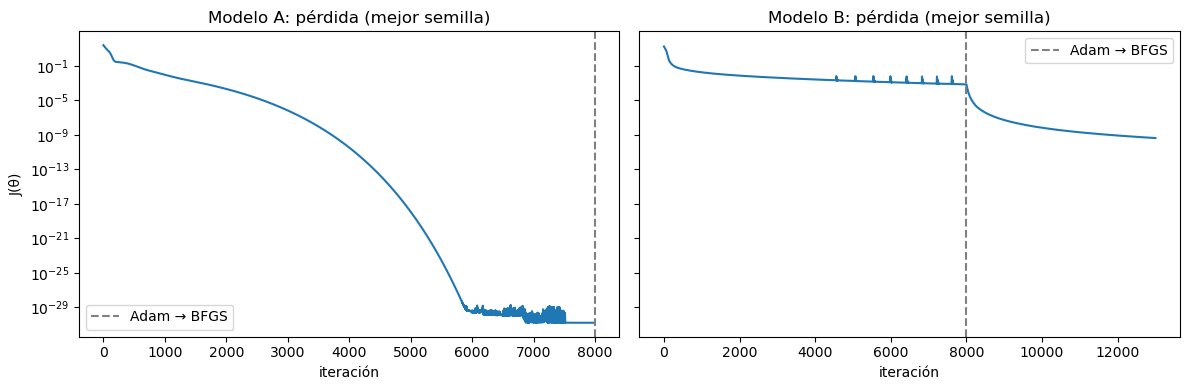

Modelo A: J = 1.71e-31, fisica = 1.71e-31, U0 = 0.00e+00, Ut0 = 0.00e+00
Modelo B: J = 4.25e-10, fisica = 4.25e-10, U0 = 4.03e-15, Ut0 = 4.03e-15


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for k, nombre in enumerate(["A", "B"]):
    R = resultados[nombre]
    ax[k].semilogy(R["hist"])
    ax[k].axvline(R["n_adam"], color="gray", ls="--", label="Adam → BFGS")
    ax[k].set_title(f"Modelo {nombre}: pérdida (mejor semilla)")
    ax[k].set_xlabel("iteración"); ax[k].legend()
ax[0].set_ylabel("J(θ)")
plt.tight_layout(); plt.show()

for nombre in ["A", "B"]:
    d = perdida(resultados[nombre]["theta"], resultados[nombre]["modelo"], detalle=True)
    print(f"Modelo {nombre}: " + ", ".join(f"{k} = {v:.2e}" for k, v in d.items()))

## Comparación con la solución analítica

Se evalúa en $t\in[0,6]$: la región sombreada es el intervalo de entrenamiento $[0,3]$; lo que queda a la derecha es extrapolación para ver como se comportan los modelos.

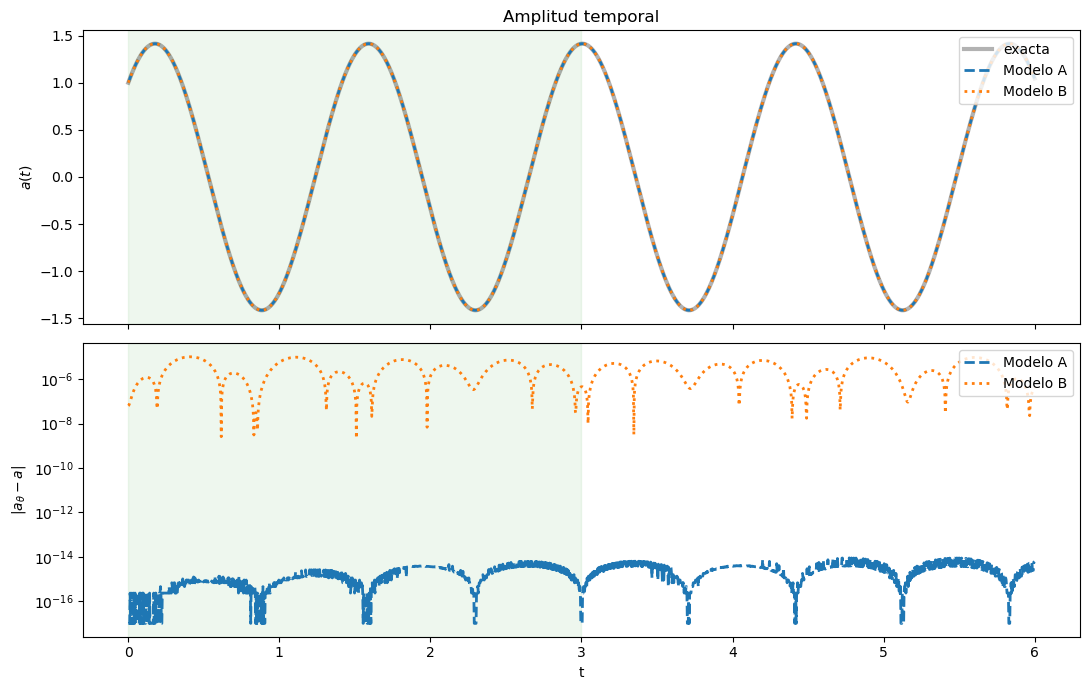

In [12]:
t_eval = np.linspace(0, 6, 2000).reshape(-1, 1)
entreno = t_eval[:, 0] <= T_final

def evaluar(nombre, t):
    R = resultados[nombre]
    (a, _), (at, _), (att, _) = R["modelo"](R["theta"], t)
    return a[:, 0], at[:, 0], att[:, 0]

a_ex, at_ex = a_exacta(t_eval[:, 0]), da_exacta(t_eval[:, 0])

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(t_eval, a_ex, "k", lw=3, alpha=0.3, label="exacta")
for nombre, est in [("A", "--"), ("B", ":")]:
    a, _, _ = evaluar(nombre, t_eval)
    ax[0].plot(t_eval, a, est, lw=2, label=f"Modelo {nombre}")
    ax[1].semilogy(t_eval, np.abs(a - a_ex) + 1e-17, est, lw=2, label=f"Modelo {nombre}")
for a_ in ax:
    a_.axvspan(0, T_final, color="C2", alpha=0.08)
    a_.legend(loc="upper right")
ax[0].set_ylabel(r"$a(t)$"); ax[0].set_title("Amplitud temporal")
ax[1].set_ylabel(r"$|a_\theta - a|$"); ax[1].set_xlabel("t")
plt.tight_layout(); plt.show()

### Errores de aproximación

Como $U_\theta-U=\sin(\pi x)\sin(\pi y)\,(a_\theta-a)$, el error relativo $L^2$ en $(x,y,t)$ coincide con el error relativo $L^2$ de $a(t)$, y el error máximo de $U$ es el error máximo de $a$ (el máximo de $\sin\sin$ es 1, en el centro).

In [13]:
def errores(a, a_ex):
    return dict(L2_rel=np.linalg.norm(a - a_ex)/np.linalg.norm(a_ex),
                max_abs=np.max(np.abs(a - a_ex)))

print(f"{'':10s}{'L2 rel [0,3]':>15s}{'max [0,3]':>13s}{'L2 rel [3,6]':>15s}{'max [3,6]':>13s}")
for nombre in ["A", "B"]:
    a, _, _ = evaluar(nombre, t_eval)
    e_in  = errores(a[entreno],  a_ex[entreno])
    e_out = errores(a[~entreno], a_ex[~entreno])
    print(f"Modelo {nombre:3s}{e_in['L2_rel']:15.2e}{e_in['max_abs']:13.2e}"
          f"{e_out['L2_rel']:15.2e}{e_out['max_abs']:13.2e}")

             L2 rel [0,3]    max [0,3]   L2 rel [3,6]    max [3,6]
Modelo A         2.09e-15     6.23e-15       3.59e-15     8.92e-15
Modelo B         4.45e-06     1.02e-05       4.20e-06     9.55e-06


## Conservación de la energía

Podemos $E(t)$ para la solución analítica de forma exacta. Teniendo en cuenta que $ \int_0^1\!\int_0^1\sin^2(\pi x)\sin^2(\pi y)\,dx\,dy=\tfrac14 $.

$$E(t)=\frac18\left[a'(t)^2+2\pi^2a(t)^2\right],\qquad E_{\rm exacta}=\frac18\left[2\pi^2+2\pi^2\right]=\frac{\pi^2}{2}\approx4.9348 .$$


Y podemos usar **cuadratura numérica** para integral la expresión exacta.

In [14]:
def energia(a, at):
    return (at**2 + w02*a**2)/8

# Verificación de la fórmula con integración numérica en t = 0.7 (solución exacta)
tk = 0.7
xq = np.linspace(0, 1, 401)
Xq, Yq = np.meshgrid(xq, xq, indexing="ij")
Sx = np.sin(np.pi*Xq); Sy = np.sin(np.pi*Yq)
Ut = Sx*Sy*da_exacta(tk)
Ux = np.pi*np.cos(np.pi*Xq)*Sy*a_exacta(tk)
Uy = np.pi*Sx*np.cos(np.pi*Yq)*a_exacta(tk)
E_num = 0.5*np.trapezoid(np.trapezoid(Ut**2 + Ux**2 + Uy**2, xq, axis=1), xq)
print("E por cuadratura 2D:", E_num, "  E fórmula:", energia(a_exacta(tk), da_exacta(tk)), "  pi^2/2:", E_exacta)

E por cuadratura 2D: 4.934802200544679   E fórmula: 4.934802200544679   pi^2/2: 4.934802200544679


Modelo A: max |ΔE|/E en [0,3] = 5.40e-16, en [3,6] = 5.40e-16
Modelo B: max |ΔE|/E en [0,3] = 2.14e-05, en [3,6] = 2.14e-05


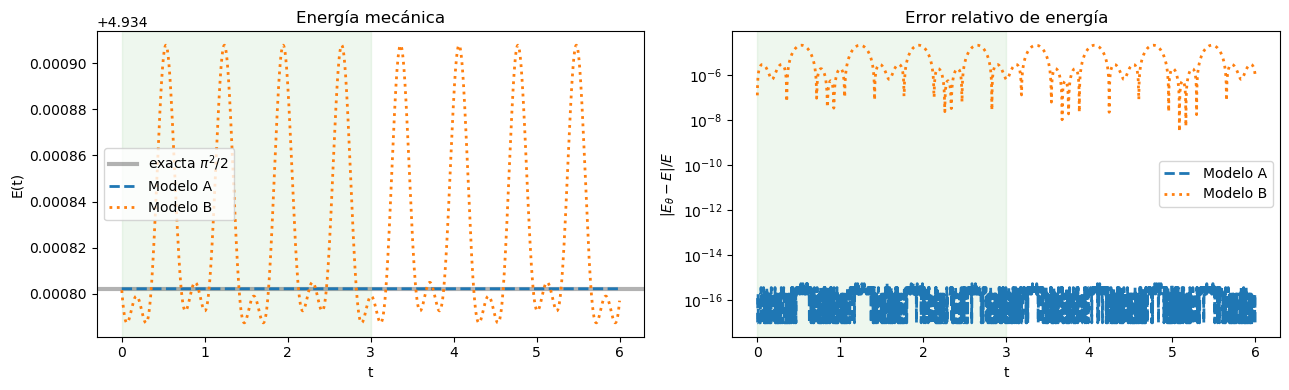

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].axhline(E_exacta, color="k", lw=3, alpha=0.3, label=r"exacta $\pi^2/2$")
for nombre, est in [("A", "--"), ("B", ":")]:
    a, at, _ = evaluar(nombre, t_eval)
    E = energia(a, at)
    ax[0].plot(t_eval, E, est, lw=2, label=f"Modelo {nombre}")
    ax[1].semilogy(t_eval, np.abs(E - E_exacta)/E_exacta + 1e-17, est, lw=2, label=f"Modelo {nombre}")
    print(f"Modelo {nombre}: max |ΔE|/E en [0,3] = {np.max(np.abs(E[entreno]-E_exacta))/E_exacta:.2e}, "
          f"en [3,6] = {np.max(np.abs(E[~entreno]-E_exacta))/E_exacta:.2e}")
for a_ in ax:
    a_.axvspan(0, T_final, color="C2", alpha=0.08); a_.legend(); a_.set_xlabel("t")
ax[0].set_ylabel("E(t)"); ax[0].set_title("Energía mecánica")
ax[1].set_ylabel(r"$|E_\theta-E|/E$"); ax[1].set_title("Error relativo de energía")
plt.tight_layout(); plt.show()

También se puede comprobar $dE/dt=0$ directamente: $\;\dfrac{dE}{dt}=\tfrac14\,a'\,(a''+\omega_0^2a)=\tfrac{\omega_0^2}{4}\,a'\,r_\theta$.

la energía se conserva exactamente donde el residuo físico es cero y  la derivda de energía de la PINN es una medida directa de qué tan bien se cumple la EDO.

## Análisis

Ambos modelos logran entrenarse de manera satisfactoria y logran recrear la solución a la ecuación diferencial. Sin embargo, el modelo A es mucho más preciso, con una perdida menor con menos iteraciones. El error también es menor.